# FD003 — is the landscape actually flat? (internal)

The two-stage run keeps returning "tie", which implies a CNN-LSTM reaches roughly the same RMSE
whatever its size and settings. That is a strong claim and it should be tested directly rather
than inferred from searches that all started at or near the baseline.

**Part 1 - landscape probe.** Evaluate a deliberately spread set of configurations: 8 units wide,
384 units wide, learning rate 1e-5, learning rate 5e-2, dropout 0.5, L2 0.1, and so on. This
measures the **dynamic range** of the space. If a 30x change in width moves RMSE by 0.2, the space
really is flat and no optimizer can help. If it moves RMSE by 5, the space is not flat and the
searches were failing to explore it.

**Part 2 - searches that start far from the baseline.** Both a Gaussian-process Bayesian search and
a particle swarm are written here rather than taken from a library, so the initial design is under
our control. Both:

- **start far** — every initial point is drawn from the region of the normalised space furthest
  from the baseline, so nothing begins in the neighbourhood we already know;
- **contain the baseline in the population** — it is evaluated and available to the model/swarm,
  but it is not the incumbent and not a starting position.

Then we watch whether the search **travels toward the baseline region**. If it converges back to
baseline-like settings from a cold start, the baseline is genuinely a good optimum and the tie is
real. If it converges somewhere else that is just as good, the surface has many equivalent optima.
If it stays where it started and never improves, the searches are not exploring and every previous
conclusion is suspect.

Distance to the baseline is tracked at every step so this is measured, not eyeballed.

Same architecture, preprocessing and training budget as the two-stage notebook
(120 epochs, patience 20). Test is recorded for diagnosis only.

In [1]:
import os, json, gc, time, random, math
os.environ['PYTHONHASHSEED']='42'
import numpy as np, pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_squared_error
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel
from scipy.stats import norm, spearmanr
import tensorflow as tf
for _g in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(_g,True)
    except RuntimeError as _e: print('memory growth:',_e)
from tensorflow.keras import backend as K, regularizers
from tensorflow.keras.layers import (Input, Conv1D, MaxPooling1D, Dropout, Dense, LSTM,
                                     Concatenate, Flatten, GlobalAveragePooling1D)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
def set_seeds(s):
    os.environ['PYTHONHASHSEED']=str(s); random.seed(s); np.random.seed(s)
    tf.keras.utils.set_random_seed(s)
def gpu_preflight():
    if not tf.config.list_physical_devices('GPU'): print('CPU mode'); return False
    try:
        x=np.random.rand(8,10,3).astype('float32'); y=np.random.rand(8,1).astype('float32')
        i=Input(shape=(10,3)); o=Dense(1)(GlobalAveragePooling1D()(Conv1D(4,3,padding='same')(i)))
        m=Model(i,o); m.compile('adam','mse'); m.fit(x,y,epochs=1,verbose=0); K.clear_session()
        print('GPU preflight passed'); return True
    except Exception as e:
        print('GPU preflight FAILED (%s)'%type(e).__name__); K.clear_session(); return False
USE_GPU=gpu_preflight(); DEVICE='/GPU:0' if USE_GPU else '/CPU:0'
try: tf.config.experimental.enable_op_determinism()
except Exception as e: print('determinism:',e)
print('TF',tf.__version__,'| device',DEVICE)

GPU preflight passed
TF 2.10.0 | device /GPU:0


In [2]:
SEED=42; RUL_CAP=125; W=50
EPOCHS, PATIENCE = 120, 20
PROBE_SEEDS, SEARCH_SEEDS, CONFIRM_SEEDS = 2, 2, 8
BO_INIT, BO_ITERS   = 6, 18
PSO_PART, PSO_ITERS = 6, 4
TESTLIKE_PER_UNIT, TESTLIKE_SEED = 50, 12345
set_seeds(SEED)

idx=['unit_nr','time_cycles']; setn=['setting_1','setting_2','setting_3']
sn=[f's_{i}' for i in range(1,22)]; cols=idx+setn+sn
train=pd.read_csv('train_FD003.txt',sep=r'\s+',header=None,names=cols)
test =pd.read_csv('test_FD003.txt', sep=r'\s+',header=None,names=cols)
y_test=pd.read_csv('RUL_FD003.txt',sep=r'\s+',header=None,names=['RUL'])
_g=GroupShuffleSplit(n_splits=1,train_size=0.8,random_state=SEED)
_ti,_vi=next(_g.split(train,groups=train.unit_nr))
TRAIN_UNITS=np.sort(train.iloc[_ti].unit_nr.unique()); VAL_UNITS=np.sort(train.iloc[_vi].unit_nr.unique())
assert not set(TRAIN_UNITS)&set(VAL_UNITS)
feats=setn+sn+['time_cycles']
tr=train.copy(); mx=tr.groupby('unit_nr')['time_cycles'].transform('max')
tr['RUL']=(mx-tr['time_cycles']).clip(upper=RUL_CAP); te=test.copy()
sc=MinMaxScaler().fit(tr[tr.unit_nr.isin(TRAIN_UNITS)][feats])
tr[feats]=np.nan_to_num(sc.transform(tr[feats])); te[feats]=np.nan_to_num(sc.transform(te[feats]))
def win_ex(df,us):
    X,y=[],[]
    for u in us:
        d=df[df.unit_nr==u]; A=d[feats].to_numpy(np.float32); L=d['RUL'].to_numpy(np.float32)
        for e in range(W,len(d)+1): X.append(A[e-W:e]); y.append(L[e-1])
    return np.asarray(X,np.float32),np.asarray(y,np.float32).reshape(-1,1)
def win_tl(df,us,rng,per):
    X,y=[],[]
    for u in us:
        d=df[df.unit_nr==u]; A=d[feats].to_numpy(np.float32); L=d['RUL'].to_numpy(np.float32); n=len(d)
        if n<W: continue
        for cut in rng.integers(W,n+1,size=per): X.append(A[cut-W:cut]); y.append(L[cut-1])
    return np.asarray(X,np.float32),np.asarray(y,np.float32).reshape(-1,1)
Xtr,ytr=win_ex(tr,TRAIN_UNITS); Xve,yve=win_ex(tr,VAL_UNITS)
Xvt,yvt=win_tl(tr,VAL_UNITS,np.random.default_rng(TESTLIKE_SEED),TESTLIKE_PER_UNIT)
Xte=[]
for u in te.unit_nr.unique():
    A=te[te.unit_nr==u][feats].to_numpy(np.float32)
    Xte.append(A[-W:] if len(A)>=W else np.vstack([np.repeat(A[:1],W-len(A),axis=0),A]))
Xte=np.asarray(Xte,np.float32); yte=np.clip(y_test['RUL'].to_numpy(np.float32),0,RUL_CAP).reshape(-1,1)
print('train %s | val_exh %s | val_tl %s | test %s'%(Xtr.shape,Xve.shape,Xvt.shape,Xte.shape))

def build(filters=128,lstm_units=128,dense=128,merged=256,dropout=0.2,l2reg=0.01,lr=1e-3,seed=SEED):
    kw=dict(kernel_initializer=tf.keras.initializers.GlorotUniform(seed=seed))
    inp=Input(shape=(W,len(feats)))
    c=Conv1D(filters,3,padding='same',activation='relu',**kw)(inp)
    c=MaxPooling1D(2,padding='same')(c); c=Flatten()(c)
    c=Dense(dense,activation='relu',kernel_regularizer=regularizers.l2(l2reg),**kw)(c)
    c=Dropout(dropout,seed=seed)(c)
    r=LSTM(lstm_units,return_sequences=True,**kw)(inp)
    r=LSTM(lstm_units,activation='tanh',**kw)(r)
    r=Dense(dense,activation='relu',kernel_regularizer=regularizers.l2(l2reg),**kw)(r)
    r=Dropout(dropout,seed=seed)(r)
    h=Concatenate()([c,r])
    h=Dense(merged,activation='relu',kernel_regularizer=regularizers.l2(l2reg),**kw)(h)
    h=Dropout(dropout,seed=seed)(h)
    m=Model(inp,Dense(1,activation='linear',**kw)(h))
    m.compile(optimizer=tf.keras.optimizers.Adam(lr),loss='mse'); return m

def evaluate(kw,seed):
    kw=dict(kw); batch=int(kw.pop('batch',512))
    K.clear_session(); gc.collect(); set_seeds(seed); t0=time.time()
    with tf.device(DEVICE):
        m=build(seed=seed,**kw)
        h=m.fit(Xtr,ytr,validation_data=(Xve,yve),epochs=EPOCHS,batch_size=batch,verbose=0,
                callbacks=[EarlyStopping('val_loss',patience=PATIENCE,restore_best_weights=True),
                           ReduceLROnPlateau('val_loss',factor=0.5,patience=8,min_lr=1e-6)])
        rm=lambda X,y: float(np.sqrt(mean_squared_error(y,m.predict(X,batch_size=1024,verbose=0))))
        o=dict(val_exh=rm(Xve,yve),val_tl=rm(Xvt,yvt),test=rm(Xte,yte),
               params=int(m.count_params()),epochs_run=len(h.history['loss']),secs=round(time.time()-t0,1))
    o['obj']=0.5*(o['val_exh']+o['val_tl']); return o

def agg(kw,n,seed0=SEED):
    rs=[evaluate(kw,seed0+s) for s in range(n)]
    a={k:float(np.mean([r[k] for r in rs])) for k in ('val_exh','val_tl','test','obj','epochs_run','secs')}
    a['test_std']=float(np.std([r['test'] for r in rs],ddof=1)) if n>1 else 0.0
    a['params']=rs[0]['params']; return a

DEFAULTS=dict(filters=128,lstm_units=128,dense=128,merged=256,dropout=0.2,l2reg=0.01,lr=1e-3,batch=512)

train (16092, 50, 25) | val_exh (3728, 50, 25) | val_tl (1000, 50, 25) | test (100, 50, 25)


## Part 1 — how flat is the space really?

Deliberately extreme configurations. If these all land within a few tenths of each other, the
"tie" verdict is a property of the problem. If they span several RMSE, the searches were the
problem.

In [3]:
PROBE={
 'baseline'          : DEFAULTS,
 'tiny (8 units)'    : dict(DEFAULTS,filters=8,lstm_units=8,dense=8,merged=16),
 'small (32)'        : dict(DEFAULTS,filters=32,lstm_units=32,dense=32,merged=64),
 'wide (384)'        : dict(DEFAULTS,filters=384,lstm_units=256,dense=384,merged=512),
 'lr 1e-5 (tiny)'    : dict(DEFAULTS,lr=1e-5),
 'lr 5e-2 (huge)'    : dict(DEFAULTS,lr=5e-2),
 'dropout 0.5'       : dict(DEFAULTS,dropout=0.5),
 'dropout 0.0'       : dict(DEFAULTS,dropout=0.0),
 'l2 0.1 (heavy)'    : dict(DEFAULTS,l2reg=0.1),
 'l2 1e-8 (none)'    : dict(DEFAULTS,l2reg=1e-8),
 'batch 128'         : dict(DEFAULTS,batch=128),
 'tiny + no reg'     : dict(DEFAULTS,filters=8,lstm_units=8,dense=8,merged=16,dropout=0.0,l2reg=1e-8),
}
rows=[]; t0=time.time()
for nm,kw in PROBE.items():
    a=agg(kw,PROBE_SEEDS)
    rows.append(dict(config=nm,**a))
    print('%-18s obj %6.3f | val_exh %6.3f | test %6.3f +/- %5.3f | params %9s | ep %3.0f | %4.0fs'
          %(nm,a['obj'],a['val_exh'],a['test'],a['test_std'],format(a['params'],','),a['epochs_run'],a['secs']))
P=pd.DataFrame(rows); P.to_csv('landscape_probe_fd003.csv',index=False)
pd.set_option('display.width',210)
print('\nprobe finished in %.0f s'%(time.time()-t0))
print('\n=== dynamic range of the space ===')
print('test RMSE spans %.3f .. %.3f  (range %.3f)'%(P.test.min(),P.test.max(),P.test.max()-P.test.min()))
print('objective spans %.3f .. %.3f  (range %.3f)'%(P.obj.min(),P.obj.max(),P.obj.max()-P.obj.min()))
print('typical seed noise (std within a config): %.3f'%P.test_std.mean())
print('range / noise ratio: %.1f'%((P.test.max()-P.test.min())/max(P.test_std.mean(),1e-6)))
b=P[P.config=='baseline'].iloc[0]
print('\nbaseline test %.3f | best probe %.3f (%s) | worst %.3f (%s)'
      %(b.test,P.test.min(),P.loc[P.test.idxmin(),'config'],P.test.max(),P.loc[P.test.idxmax(),'config']))
print('\nparameter count spans %s .. %s (%.0fx)'
      %(format(P.params.min(),','),format(P.params.max(),','),P.params.max()/max(P.params.min(),1)))
print(P[['config','obj','test','test_std','params','epochs_run']].sort_values('test').to_string(index=False))

baseline           obj  8.841 | val_exh  8.475 | test 10.723 +/- 0.005 | params   712,449 | ep  92 |   35s
tiny (8 units)     obj 14.183 | val_exh 14.024 | test 14.615 +/- 1.476 | params     4,209 | ep  68 |   22s
small (32)         obj 12.094 | val_exh 11.636 | test 12.922 +/- 1.153 | params    49,089 | ep  56 |   19s
wide (384)         obj  8.599 | val_exh  8.201 | test 11.044 +/- 0.701 | params 5,022,977 | ep  76 |   41s
lr 1e-5 (tiny)     obj 14.935 | val_exh 14.555 | test 17.151 +/- 1.426 | params   712,449 | ep 120 |   45s
lr 5e-2 (huge)     obj 14.761 | val_exh 14.209 | test 15.779 +/- 4.036 | params   712,449 | ep  52 |   21s
dropout 0.5        obj  9.118 | val_exh  8.856 | test 10.633 +/- 0.228 | params   712,449 | ep  92 |   35s
dropout 0.0        obj  9.323 | val_exh  8.952 | test 10.474 +/- 0.293 | params   712,449 | ep  84 |   31s
l2 0.1 (heavy)     obj  8.759 | val_exh  8.433 | test 10.422 +/- 0.019 | params   712,449 | ep 117 |   43s
l2 1e-8 (none)     obj  9.241 | val_e

## Part 2 — searches launched far from the baseline

Both searches are implemented here so the initial design is controlled. Every starting point is
drawn from the far region of the normalised space; the baseline is added to the population but is
never the incumbent or a starting position.

In [4]:
SPACE=[('filters',32,384,'int'),('lstm_units',32,256,'int'),('dense',32,384,'int'),
       ('merged',64,512,'int'),('dropout',0.0,0.5,'float'),
       ('lr',1e-4,2e-2,'log'),('l2reg',1e-8,1e-1,'log')]
D=len(SPACE)
def decode(v):
    kw={}
    for (n,lo,hi,k),x in zip(SPACE,np.clip(v,0,1)):
        if k=='int': kw[n]=int(round(lo+x*(hi-lo)))
        elif k=='log': kw[n]=float(math.exp(math.log(lo)+x*(math.log(hi)-math.log(lo))))
        else: kw[n]=float(lo+x*(hi-lo))
    kw['batch']=512; return kw
def encode(kw):
    v=[]
    for n,lo,hi,k in SPACE:
        x=kw[n]
        v.append((math.log(max(x,lo))-math.log(lo))/(math.log(hi)-math.log(lo)) if k=='log'
                 else (x-lo)/(hi-lo))
    return np.clip(np.array(v,float),0,1)
BASE_VEC=encode(DEFAULTS)
dist=lambda v: float(np.linalg.norm(np.asarray(v)-BASE_VEC))

rng=np.random.RandomState(SEED)
pool=rng.rand(4000,D); dists=np.linalg.norm(pool-BASE_VEC,axis=1)
FAR=np.percentile(dists,90)
print('normalised distance to baseline: random points median %.2f, 90th pct %.2f, max possible %.2f'
      %(np.median(dists),FAR,math.sqrt(D)))
def far_points(n,seed):
    r=np.random.RandomState(seed); out=[]
    while len(out)<n:
        c=r.rand(2000,D); d=np.linalg.norm(c-BASE_VEC,axis=1)
        out += list(c[d>=FAR])
    return np.array(out[:n])

EVAL_CACHE={}
def fitness(v,tag=''):
    key=tuple(np.round(v,6))
    if key in EVAL_CACHE: return EVAL_CACHE[key]
    a=agg(decode(v),SEARCH_SEEDS)
    EVAL_CACHE[key]=a
    LOG.append(dict(tag=tag,dist=dist(v),**a,**decode(v)))
    return a
LOG=[]

# the baseline is evaluated and enters the population, but is never a start point
BASE_A=agg(DEFAULTS,SEARCH_SEEDS); EVAL_CACHE[tuple(np.round(BASE_VEC,6))]=BASE_A
LOG.append(dict(tag='baseline',dist=0.0,**BASE_A,**DEFAULTS))
print('baseline obj %.3f | test %.3f  (in the population, not a start point)'%(BASE_A['obj'],BASE_A['test']))

normalised distance to baseline: random points median 0.90, 90th pct 1.14, max possible 2.65
baseline obj 8.805 | test 10.581  (in the population, not a start point)


In [5]:
def gp_bo(n_init,n_iter,seed):
    X=list(far_points(n_init,seed)); y=[fitness(x,'bo-init')['obj'] for x in X]
    X.append(BASE_VEC.copy()); y.append(BASE_A['obj'])          # baseline joins the population
    hist=[]
    for it in range(n_iter):
        gp=GaussianProcessRegressor(
            kernel=ConstantKernel(1.0)*Matern(length_scale=np.ones(D),nu=2.5)+WhiteKernel(1e-2),
            normalize_y=True,n_restarts_optimizer=2,random_state=seed)
        gp.fit(np.array(X),np.array(y))
        cand=np.random.RandomState(seed+it).rand(3000,D)
        mu,sd=gp.predict(cand,return_std=True); best=min(y)
        z=(best-mu)/np.maximum(sd,1e-9)
        ei=(best-mu)*norm.cdf(z)+sd*norm.pdf(z)
        x=cand[int(np.argmax(ei))]
        f=fitness(x,'bo')['obj']; X.append(x); y.append(f)
        bi=int(np.argmin(y))
        hist.append(dict(it=it+1,best=min(y),dist_of_best=dist(X[bi]),new_dist=dist(x)))
        print('  BO %2d: obj %.3f | best %.3f | dist(best->baseline) %.2f | sampled at dist %.2f'
              %(it+1,f,min(y),dist(X[bi]),dist(x)))
    return np.array(X),np.array(y),pd.DataFrame(hist)

print('=== Bayesian search, cold start ===')
t0=time.time(); BX,BY,BH=gp_bo(BO_INIT,BO_ITERS,SEED)
print('done in %.0f s'%(time.time()-t0))

=== Bayesian search, cold start ===


c:\Users\Pc\.conda\envs\NCmapss_GPU\lib\site-packages\sklearn\gaussian_process\kernels.py:411: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn("The optimal value found for "
c:\Users\Pc\.conda\envs\NCmapss_GPU\lib\site-packages\sklearn\gaussian_process\kernels.py:402: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn("The optimal value found for "


  BO  1: obj 9.792 | best 8.805 | dist(best->baseline) 0.00 | sampled at dist 0.77


c:\Users\Pc\.conda\envs\NCmapss_GPU\lib\site-packages\sklearn\gaussian_process\kernels.py:411: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn("The optimal value found for "
c:\Users\Pc\.conda\envs\NCmapss_GPU\lib\site-packages\sklearn\gaussian_process\kernels.py:411: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn("The optimal value found for "
c:\Users\Pc\.conda\envs\NCmapss_GPU\lib\site-packages\sklearn\gaussian_process\kernels.py:411: ConvergenceWarning: The optimal value found for dimension 6 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a bette

  BO  2: obj 8.630 | best 8.630 | dist(best->baseline) 0.61 | sampled at dist 0.61


c:\Users\Pc\.conda\envs\NCmapss_GPU\lib\site-packages\sklearn\gaussian_process\kernels.py:411: ConvergenceWarning: The optimal value found for dimension 6 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn("The optimal value found for "
c:\Users\Pc\.conda\envs\NCmapss_GPU\lib\site-packages\sklearn\gaussian_process\kernels.py:402: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn("The optimal value found for "


... (27 outputs left out)

c:\Users\Pc\.conda\envs\NCmapss_GPU\lib\site-packages\sklearn\gaussian_process\kernels.py:411: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn("The optimal value found for "
c:\Users\Pc\.conda\envs\NCmapss_GPU\lib\site-packages\sklearn\gaussian_process\kernels.py:411: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn("The optimal value found for "
c:\Users\Pc\.conda\envs\NCmapss_GPU\lib\site-packages\sklearn\gaussian_process\kernels.py:411: ConvergenceWarning: The optimal value found for dimension 6 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a bette

  BO 17: obj 8.645 | best 8.630 | dist(best->baseline) 0.61 | sampled at dist 0.91


c:\Users\Pc\.conda\envs\NCmapss_GPU\lib\site-packages\sklearn\gaussian_process\kernels.py:411: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn("The optimal value found for "
c:\Users\Pc\.conda\envs\NCmapss_GPU\lib\site-packages\sklearn\gaussian_process\kernels.py:411: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn("The optimal value found for "
c:\Users\Pc\.conda\envs\NCmapss_GPU\lib\site-packages\sklearn\gaussian_process\kernels.py:411: ConvergenceWarning: The optimal value found for dimension 6 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a bette

  BO 18: obj 11.770 | best 8.630 | dist(best->baseline) 0.61 | sampled at dist 0.97
done in 1623 s


In [6]:
def pso_far(n_part,iters,seed,w=0.72,c1=1.5,c2=1.5):
    r=np.random.RandomState(seed)
    X=far_points(n_part,seed)                       # every particle starts far away
    V=r.uniform(-0.1,0.1,(n_part,D))
    f=np.array([fitness(x,'pso-init')['obj'] for x in X])
    P=X.copy(); Pf=f.copy()
    # the baseline joins the population as an extra memory, not as a particle position
    G=BASE_VEC.copy() if BASE_A['obj']<Pf.min() else P[int(np.argmin(Pf))].copy()
    Gf=min(BASE_A['obj'],float(Pf.min()))
    print('  init: swarm best %.3f at mean distance %.2f | baseline %.3f'
          %(Pf.min(),np.mean([dist(x) for x in X]),BASE_A['obj']))
    hist=[]
    for it in range(iters):
        r1,r2=r.rand(n_part,D),r.rand(n_part,D)
        V=np.clip(w*V+c1*r1*(P-X)+c2*r2*(G-X),-0.25,0.25); X=np.clip(X+V,0,1)
        f=np.array([fitness(x,'pso')['obj'] for x in X])
        imp=f<Pf; P[imp]=X[imp]; Pf[imp]=f[imp]
        if Pf.min()<Gf: Gf=float(Pf.min()); G=P[int(np.argmin(Pf))].copy()
        md_=float(np.mean([dist(x) for x in X]))
        hist.append(dict(it=it+1,best=Gf,mean_dist=md_,dist_of_best=dist(G)))
        print('  PSO %d: best %.3f | swarm mean dist %.2f | dist(best->baseline) %.2f'
              %(it+1,Gf,md_,dist(G)))
    return G,Gf,pd.DataFrame(hist)

print('=== particle swarm, cold start ===')
t0=time.time(); PG,PGf,PH=pso_far(PSO_PART,PSO_ITERS,SEED)
print('done in %.0f s'%(time.time()-t0))
L=pd.DataFrame(LOG); L.to_csv('coldstart_log_fd003.csv',index=False)

=== particle swarm, cold start ===
  init: swarm best 9.759 at mean distance 1.25 | baseline 8.805
  PSO 1: best 8.734 | swarm mean dist 0.80 | dist(best->baseline) 0.82
  PSO 2: best 8.648 | swarm mean dist 0.56 | dist(best->baseline) 0.37
  PSO 3: best 8.648 | swarm mean dist 0.46 | dist(best->baseline) 0.37
  PSO 4: best 8.648 | swarm mean dist 0.52 | dist(best->baseline) 0.37
done in 1664 s


## What happened

In [7]:
print('=== 1. is the space flat? ===')
rng_test=P.test.max()-P.test.min()
print('landscape probe test range %.3f vs typical seed noise %.3f -> %s'
      %(rng_test,P.test_std.mean(),
        'NOT flat, configuration matters' if rng_test>3*P.test_std.mean() else 'genuinely flat'))
print()
print('=== 2. did the cold-start searches walk back to the baseline? ===')
print('BO : best-so-far distance to baseline %.2f -> %.2f'%(BH.dist_of_best.iloc[0],BH.dist_of_best.iloc[-1]))
print('PSO: swarm mean distance %.2f -> %.2f | best at distance %.2f'
      %(PH.mean_dist.iloc[0],PH.mean_dist.iloc[-1],PH.dist_of_best.iloc[-1]))
print()
print('=== 3. did anything beat the baseline from a cold start? ===')
srch=L[L.tag!='baseline']
bb=srch.nsmallest(1,'obj').iloc[0]
print('baseline           obj %.3f | test %.3f'%(BASE_A['obj'],BASE_A['test']))
print('best found (cold)  obj %.3f | test %.3f | distance from baseline %.2f'%(bb['obj'],bb['test'],bb['dist']))
print()
print('=== 4. does distance from the baseline predict quality? ===')
r,p=spearmanr(srch['dist'],srch['obj'])
print('Spearman(distance, objective) = %+.3f (p=%.3f) -> %s'
      %(r,p,'the baseline region is genuinely special' if r>0.4 else
            'quality is unrelated to being near the baseline'))
print()
print('confirming the best cold-start find on %d fresh seeds:'%CONFIRM_SEEDS)
kwb={n:(int(bb[n]) if k=='int' else float(bb[n])) for n,_,_,k in SPACE}; kwb['batch']=512
cb=agg(kwb,CONFIRM_SEEDS,SEED+7000); cbase=agg(DEFAULTS,CONFIRM_SEEDS,SEED+7000)
print('  baseline       test %.3f +/- %.3f'%(cbase['test'],cbase['test_std']))
print('  cold-start best test %.3f +/- %.3f'%(cb['test'],cb['test_std']))
d=cb['test']-cbase['test']; nz=math.sqrt(cb['test_std']**2+cbase['test_std']**2)
print('  difference %+.3f vs noise %.3f -> %s'%(d,nz,'REAL' if abs(d)>nz else 'tie'))
json.dump(dict(probe=P.to_dict('records'),bo_hist=BH.to_dict('records'),
               pso_hist=PH.to_dict('records'),log=LOG,
               baseline=BASE_A,cold_best=dict(bb),confirm=dict(base=cbase,cold=cb)),
          open('coldstart_fd003.json','w'),indent=2,default=str)
print('\nsaved landscape_probe_fd003.csv, coldstart_log_fd003.csv, coldstart_fd003.json')

=== 1. is the space flat? ===
landscape probe test range 6.729 vs typical seed noise 0.868 -> NOT flat, configuration matters

=== 2. did the cold-start searches walk back to the baseline? ===
BO : best-so-far distance to baseline 0.00 -> 0.61
PSO: swarm mean distance 0.80 -> 0.52 | best at distance 0.37

=== 3. did anything beat the baseline from a cold start? ===
baseline           obj 8.805 | test 10.581
best found (cold)  obj 8.630 | test 11.274 | distance from baseline 0.61

=== 4. does distance from the baseline predict quality? ===
Spearman(distance, objective) = +0.595 (p=0.000) -> the baseline region is genuinely special

confirming the best cold-start find on 8 fresh seeds:
  baseline       test 11.061 +/- 0.550
  cold-start best test 11.016 +/- 0.169
  difference -0.045 vs noise 0.575 -> tie

saved landscape_probe_fd003.csv, coldstart_log_fd003.csv, coldstart_fd003.json


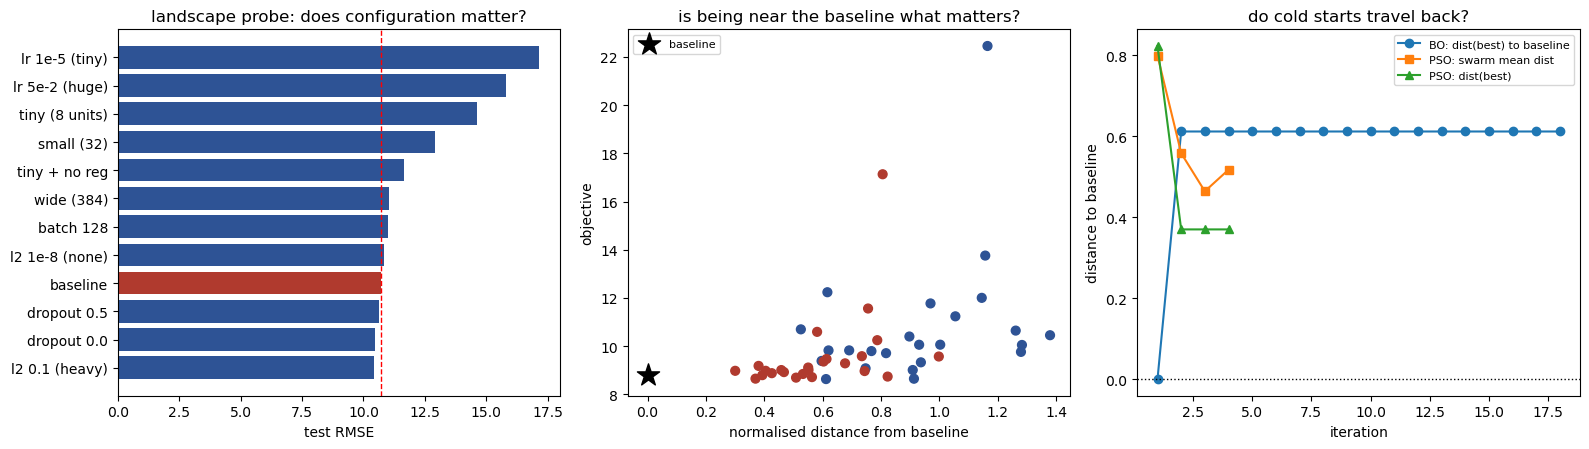

In [8]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,3,figsize=(16,4.6))
Ps=P.sort_values('test')
ax[0].barh(Ps.config,Ps.test,color=['#B03A2E' if c=='baseline' else '#2E5395' for c in Ps.config])
ax[0].set_xlabel('test RMSE'); ax[0].set_title('landscape probe: does configuration matter?')
ax[0].axvline(P[P.config=='baseline'].test.iloc[0],color='r',ls='--',lw=1)
s=L[L.tag!='baseline']
ax[1].scatter(s['dist'],s['obj'],c=['#B03A2E' if 'pso' in t else '#2E5395' for t in s['tag']],s=40)
ax[1].scatter([0],[BASE_A['obj']],marker='*',s=280,c='k',label='baseline',zorder=5)
ax[1].set_xlabel('normalised distance from baseline'); ax[1].set_ylabel('objective')
ax[1].set_title('is being near the baseline what matters?'); ax[1].legend(fontsize=8)
ax[2].plot(BH.it,BH.dist_of_best,marker='o',label='BO: dist(best) to baseline')
ax[2].plot(PH.it,PH.mean_dist,marker='s',label='PSO: swarm mean dist')
ax[2].plot(PH.it,PH.dist_of_best,marker='^',label='PSO: dist(best)')
ax[2].axhline(0,color='k',ls=':',lw=1); ax[2].set_xlabel('iteration')
ax[2].set_ylabel('distance to baseline'); ax[2].legend(fontsize=8)
ax[2].set_title('do cold starts travel back?')
plt.tight_layout(); plt.show()